# SEM.9.7 — Notebook 3: Planform change and channel width, 2000–2026

Reproducibility notebook for **SFFS technical report SEM.9.7, *Geomorphic Evolution of the Lower Semliki: Bed and Bank Change, 2000–2026*** (Ministry of Water and Environment, Uganda, 2026), Sections 4.2 and 5.

The 27 annual Landsat masks are combined into **majority composites** for five epochs (2000–04, 2005–09, 2010–14, 2015–19, 2020–26), keeping only water connected to the main channel. Land in 2000–04 that is channel in 2020–26 is mapped as **eroded**; channel in 2000–04 that is land in 2020–26 as **deposited or abandoned**; channel in both as **stable**. The same masks give the low-flow channel width of each year by zone.

Uses only `data/masks/landsat_2000_2026/` and the published baseline (`data/results/landsat_2000_2026/transects.csv`). Runtime: under a minute.

In [1]:
import os, zipfile
if not os.path.isdir("data"):      # the masks and published results ship as one zip beside the notebooks
    zipfile.ZipFile("SEM.9.7_data_masks_and_results.zip").extractall(".")

In [2]:
import os, glob, re, csv, json
import numpy as np
from scipy import ndimage
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

DATA = os.path.abspath("data"); OUT = os.path.abspath("outputs"); os.makedirs(OUT, exist_ok=True)
GAUGE_STATION_M = 8250.0
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

yrs = {}
for f in sorted(glob.glob(os.path.join(DATA, "masks", "landsat_2000_2026", "*.npz"))):
    z = np.load(f); y = int(re.search(r"(\d{4})", os.path.basename(f)).group(1))
    yrs[y] = (z["water"].astype(bool), z["valid"].astype(bool), z["transform"])
YEARS = sorted(yrs); T = yrs[YEARS[0]][2]; H, Wd = yrs[YEARS[0]][0].shape
x0, dx, y0, dy = T[2], T[0], T[5], T[4]
X = x0 + (np.arange(Wd) + .5) * dx; Y = y0 + (np.arange(H) + .5) * dy
EXT = [X[0] - dx / 2, X[-1] + dx / 2, Y[-1] + dy / 2, Y[0] - dy / 2]
print(len(YEARS), "masks", YEARS[0], "-", YEARS[-1], "grid", (H, Wd), "pixel", dx, "m")

tr = list(csv.DictReader(open(os.path.join(DATA, "results", "landsat_2000_2026", "transects.csv"))))
bx = np.array([float(r["x"]) for r in tr]); by = np.array([float(r["y"]) for r in tr])
bkm = (np.array([float(r["station_m"]) for r in tr]) - GAUGE_STATION_M) / 1000.0
base = np.zeros((H, Wd), bool)
ci = np.clip(((bx - x0) / dx).astype(int), 0, Wd - 1); ri = np.clip(((by - y0) / dy).astype(int), 0, H - 1)
base[ri, ci] = True
dist, (ii, jj) = ndimage.distance_transform_edt(~base, return_indices=True); dist = dist * dx
kmb = np.full((H, Wd), np.nan); kmb[ri, ci] = bkm; kmgrid = kmb[ii, jj]
CORR = dist <= 600.0          # active channel corridor, 600 m either side of the baseline

27 masks 2000 - 2026 grid (1315, 1174) pixel 30.0 m


## Epoch composites and the change between the first and last epoch

In [3]:
def main_channel(w):
    lab, n = ndimage.label(w, structure=np.ones((3, 3)))
    if n == 0:
        return w
    hit = np.unique(lab[ndimage.binary_dilation(base, iterations=3) & w]); hit = hit[hit > 0]
    sizes = ndimage.sum(w, lab, hit)
    return np.isin(lab, hit[sizes >= 30])          # >= 30 pixels (2.7 ha)

def composite(ys):
    wsum = np.zeros((H, Wd)); vsum = np.zeros((H, Wd))
    for y in ys:
        w, v, _ = yrs[y]; wsum += (w & v); vsum += v
    frac = np.where(vsum > 0, wsum / np.maximum(vsum, 1), np.nan)
    return main_channel((frac >= 0.5) & CORR), vsum > 0

EPOCHS = [(2000, 2004), (2005, 2009), (2010, 2014), (2015, 2019), (2020, 2026)]
COMP = {e: composite([y for y in YEARS if e[0] <= y <= e[1]]) for e in EPOCHS}
(W0, V0), (W1, V1) = COMP[EPOCHS[0]], COMP[EPOCHS[-1]]
both = V0 & V1
ero, dep, stay = W1 & ~W0 & both, W0 & ~W1 & both, W0 & W1
ha = lambda m: round(float(m.sum() * dx * dx / 1e4), 1)
print("eroded (land -> channel) %.1f ha, deposited/abandoned (channel -> land) %.1f ha, stable channel %.1f ha"
      % (ha(ero), ha(dep), ha(stay)))

ZONES = [("10-0 km above the gauge", -10.5, 0), ("km 0-20", 0, 20), ("km 20-40", 20, 40), ("km 40-60", 40, 60), ("km 60-92", 60, 92.5)]
span = (EPOCHS[-1][0] + EPOCHS[-1][1]) / 2 - (EPOCHS[0][0] + EPOCHS[0][1]) / 2
print("\n%-26s %10s %12s %16s %8s %8s" % ("zone", "eroded ha", "deposited ha", "reworked m/yr", "w0 m", "w1 m"))
for name, lo, hi in ZONES:
    zm = (kmgrid >= lo) & (kmgrid < hi); L = (hi - lo) * 1000.0
    e_, d_ = (ero & zm).sum() * dx * dx, (dep & zm).sum() * dx * dx
    print("%-26s %10.1f %12.1f %16.2f %8.0f %8.0f" % (name, e_ / 1e4, d_ / 1e4, (e_ + d_) / 2 / L / span,
          (W0 & zm).sum() * dx * dx / L, (W1 & zm).sum() * dx * dx / L))

eroded (land -> channel) 265.1 ha, deposited/abandoned (channel -> land) 298.8 ha, stable channel 418.1 ha

zone                        eroded ha deposited ha    reworked m/yr     w0 m     w1 m
10-0 km above the gauge          40.5         52.4             2.11       86       75
km 0-20                          72.6         63.2             1.62       76       81
km 20-40                         85.4         53.1             1.65       68       84
km 40-60                         39.1         31.1             0.84       72       76
km 60-92                         27.4         15.9             0.32       34       38


## Map: where the channel moved (report Figure ge01)

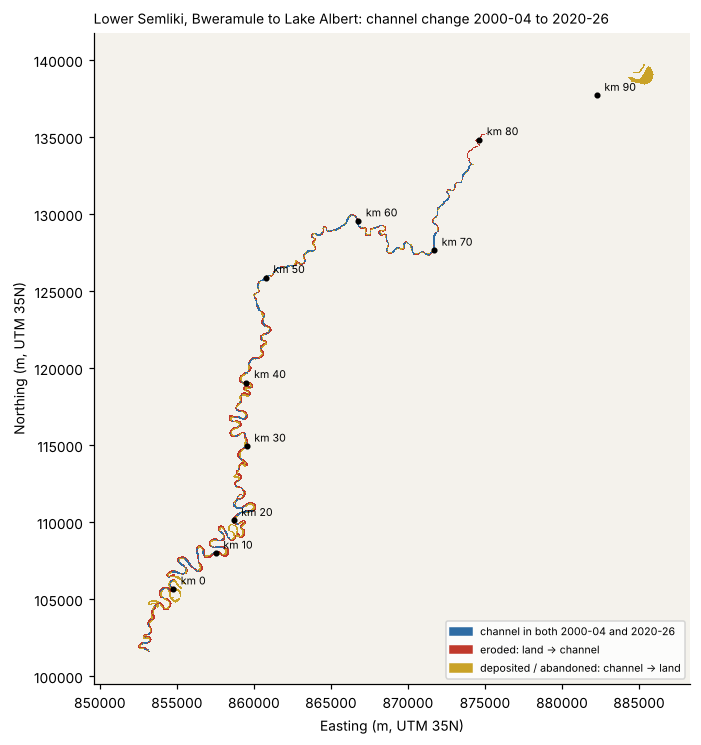

In [4]:
lay = np.full((H, Wd), np.nan); lay[stay] = 0; lay[ero] = 1; lay[dep] = 2
lay = ndimage.grey_dilation(np.nan_to_num(lay, nan=-1), size=(2, 2)); lay = np.where(lay < 0, np.nan, lay)
fig, ax = plt.subplots(figsize=(7, 8))
ax.set_facecolor("#F4F2EC")
ax.imshow(lay, extent=EXT, cmap=ListedColormap(["#2E6CA4", "#C0392B", "#C9A227"]), vmin=0, vmax=2, interpolation="nearest")
for k in range(0, 95, 10):
    i = int(np.argmin(np.abs(bkm - k))); ax.plot(bx[i], by[i], "o", ms=3, color="k"); ax.annotate("km %d" % k, (bx[i], by[i]), xytext=(5, 3), textcoords="offset points", fontsize=7)
ax.set_xlim(bx.min() - 3000, bx.max() + 3000); ax.set_ylim(by.min() - 2500, by.max() + 2500); ax.set_aspect("equal")
ax.legend(handles=[Patch(color="#2E6CA4", label="channel in both 2000-04 and 2020-26"), Patch(color="#C0392B", label="eroded: land -> channel"),
                   Patch(color="#C9A227", label="deposited / abandoned: channel -> land")], loc="lower right", fontsize=7)
ax.set_xlabel("Easting (m, UTM 35N)"); ax.set_ylabel("Northing (m, UTM 35N)")
ax.set_title("Lower Semliki, Bweramule to Lake Albert: channel change 2000-04 to 2020-26", loc="left", fontsize=9)
fig.savefig(os.path.join(OUT, "erosion_deposition_overview.png"), dpi=200, bbox_inches="tight"); plt.show()

## Channel width through time (report Section 5.2, Figure ge05)

The area of the main channel in each zone, divided by the zone length, is the mean low-flow wetted width. A zone counts only when at least 60 % of it is cloud-free; a year whose width departs more than 35 % from the zone median in any zone except the delta is treated as a bad mask (the delta zone really widens when Lake Albert floods it).

masks rejected for the width series: [2002]
10-0 km above the gauge    width trend -0.30 m/yr
km 0-20                    width trend +0.44 m/yr
km 20-40                   width trend +0.96 m/yr
km 40-60                   width trend +0.52 m/yr
km 60-92                   width trend +0.51 m/yr


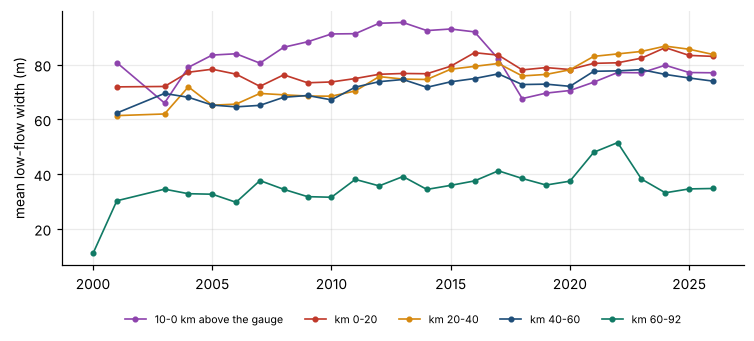

In [5]:
rows = []
for y in YEARS:
    w, v, _ = yrs[y]; mc = main_channel(w & v & CORR); rec = {"year": y}
    for name, lo, hi in ZONES:
        zm = CORR & (kmgrid >= lo) & (kmgrid < hi); vf = (v & zm).sum() / max(zm.sum(), 1)
        rec[name] = round((mc & zm).sum() * dx * dx / 1e4 / vf, 1) if vf > 0.6 else None
    rows.append(rec)
med = {n: np.median([r[n] for r in rows if r[n] is not None]) for n, _, _ in ZONES}
bad = [r["year"] for r in rows if any(r[n] is not None and abs(r[n] / med[n] - 1) > .35 for n, _, _ in ZONES[:-1])]
print("masks rejected for the width series:", bad)
fig, ax = plt.subplots(figsize=(8, 3))
for (name, lo, hi), col in zip(ZONES, ["#8E44AD", "#C0392B", "#D68910", "#1F4E79", "#117A65"]):
    ok = [r for r in rows if r["year"] not in bad and r[name] is not None]
    yy = [r["year"] for r in ok]; ww = [r[name] * 1e4 / ((hi - lo) * 1000) for r in ok]
    ax.plot(yy, ww, "o-", ms=3, lw=1.1, color=col, label=name)
    print("%-26s width trend %+.2f m/yr" % (name, np.polyfit(yy, ww, 1)[0]))
ax.set_ylabel("mean low-flow width (m)"); ax.grid(alpha=.25); ax.legend(fontsize=7, ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(.5, -.15))
fig.savefig(os.path.join(OUT, "width_by_year.png"), dpi=200, bbox_inches="tight"); plt.show()
with open(os.path.join(OUT, "channel_area_by_year.csv"), "w", newline="") as fh:
    wr = csv.DictWriter(fh, fieldnames=list(rows[0])); wr.writeheader(); wr.writerows(rows)